# ¿Se prende o se apaga? Predicción de inflamabilidad en microgravedad y gravedad parcial

**Equipo Dinamita · NASA Space Apps 2026 · Flame in Freefall**

Pregunta: para un material de cabina (PMMA, acrílico), con un nivel de oxígeno, una ventilación y una gravedad dados, ¿la llama se sostiene o se apaga?

Datos (todos públicos, con cita en `data/flammability_data.json`):
- **Entrenamiento**: 51 ensayos de BASS-II en la ISS (0 g), varillas de PMMA. Olson & Ferkul, *Combust. Flame* 180 (2017), reproducido en NASA/TM-20210011385.
- **Validación externa**: 16 ensayos en centrífuga a 0.04, 0.16, 0.38, 0.65 y 1 g (Olson et al., *Fire Safety J.* 2024). El modelo nunca los ve al entrenar.
- **Referencia**: la curva límite publicada por los autores (no se usa para entrenar).

Respondemos cinco preguntas:
1. Probabilidad de que la llama se sostenga.
2. Oxígeno mínimo para que algo se prenda en la Luna y en Marte.
3. Ventilación más peligrosa.
4. Si cortar la ventilación apaga el fuego.
5. Margen de seguridad de cada hábitat.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, brentq
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, GroupKFold
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, brier_score_loss, confusion_matrix
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
HERE = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd() / "ml"
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})
BURN, EXT = "#e8743b", "#3b7de8"

raw = json.loads((HERE / "data" / "flammability_data.json").read_text())
series = {s["id"]: s for s in raw["series"] + raw["partial_gravity"]}

ug = pd.DataFrame(series["pmma_ug_bassII_rods"]["points"])
ug = ug[ug.outcome.isin(["burn", "extinct"])].assign(y=lambda d: (d.outcome == "burn").astype(int), g=0.0)
pg = pd.DataFrame(series["pmma_rod_centrifuge_partial_g"]["points"])
pg = pg[pg.outcome.isin(["burn", "extinct"])].assign(y=lambda d: (d.outcome == "burn").astype(int), flow_cm_s=0.0).rename(columns={"gravity_g": "g"})
ref = pd.DataFrame(series["pmma_ug_bassII_boundary_fit"]["points"])
print(f"Entrenamiento (0 g): {len(ug)} ensayos | Validación (gravedad parcial): {len(pg)} ensayos")

Entrenamiento (0 g): 51 ensayos | Validación (gravedad parcial): 16 ensayos


## 1. EDA

In [2]:
display_cols = ["flow_cm_s", "o2_pct", "y"]
print(ug[display_cols].describe().round(2))
print("\nBalance de clases (0 g):", ug.y.value_counts().rename({1: "se prende", 0: "se apaga"}).to_dict())
print("Balance de clases (gravedad parcial):", pg.y.value_counts().rename({1: "se prende", 0: "se apaga"}).to_dict())

       flow_cm_s  o2_pct      y
count      51.00   51.00  51.00
mean        6.18   15.00   0.53
std         7.68    0.99   0.50
min         0.24   13.51   0.00
25%         0.76   14.36   0.00
50%         2.32   14.81   1.00
75%         9.56   15.51   1.00
max        31.65   18.01   1.00

Balance de clases (0 g): {'se prende': 27, 'se apaga': 24}
Balance de clases (gravedad parcial): {'se apaga': 9, 'se prende': 7}


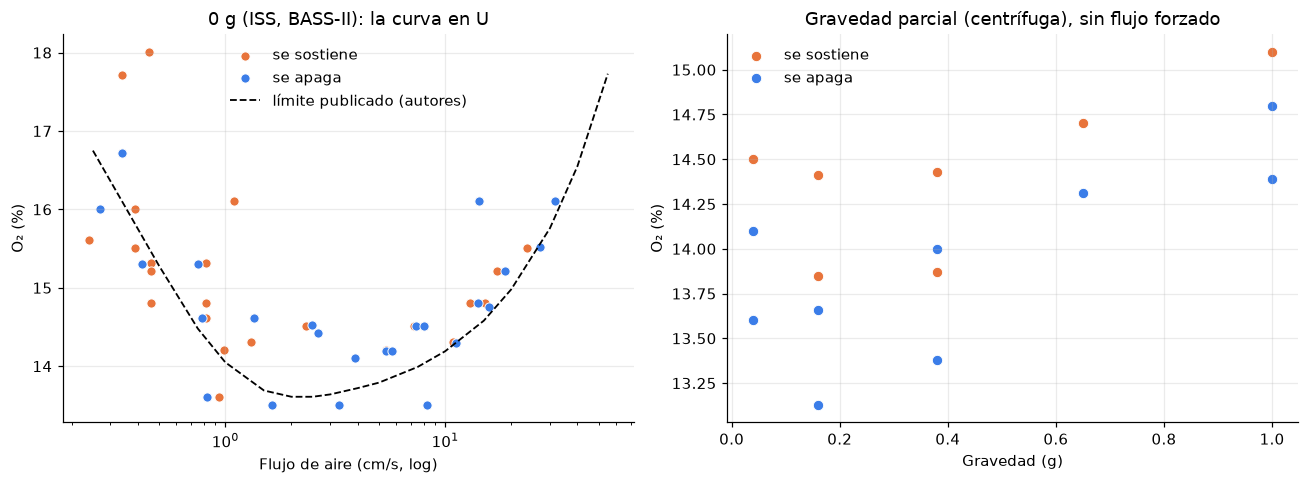

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for y, c, lab in [(1, BURN, "se sostiene"), (0, EXT, "se apaga")]:
    d = ug[ug.y == y]
    ax[0].scatter(d.flow_cm_s, d.o2_pct, c=c, label=lab, s=36, edgecolor="white", linewidth=0.6)
ax[0].plot(ref.flow_cm_s, ref.o2_pct, "k--", lw=1.2, label="límite publicado (autores)")
ax[0].set(xscale="log", xlabel="Flujo de aire (cm/s, log)", ylabel="O₂ (%)", title="0 g (ISS, BASS-II): la curva en U")
ax[0].legend(frameon=False)
for y, c, lab in [(1, BURN, "se sostiene"), (0, EXT, "se apaga")]:
    d = pg[pg.y == y]
    ax[1].scatter(d.g, d.o2_pct, c=c, label=lab, s=46, edgecolor="white", linewidth=0.6)
ax[1].set(xlabel="Gravedad (g)", ylabel="O₂ (%)", title="Gravedad parcial (centrífuga), sin flujo forzado")
ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "eda_scatter.png", bbox_inches="tight"); plt.show()

**Lectura del EDA**
- Con poco flujo (< 1 cm/s) hace falta **más** O₂: la llama pierde calor por radiación y se ahoga. Con mucho flujo también: el aire la sopla. En el medio, cerca de 2 cm/s, está el mínimo: **la ventilación más peligrosa**.
- Los dos casos casi no se separan: toda la acción ocurre entre 13.5 y 17 % de O₂.
- **Ruido experimental**: abajo contamos pares de ensayos en condiciones casi idénticas con resultado opuesto, y medimos cuánto acierta la propia curva de NASA.

**Conclusión clave del EDA:** los ensayos se hicieron a propósito *en el borde* (a menos de 1 punto de O₂ del límite), porque así se mide un límite. Ahí el resultado es casi una moneda: ni la curva publicada por NASA acierta mucho más que el azar. **No se puede predecir ensayo por ensayo cerca del límite; sí se puede predecir dónde está el límite**, y eso es lo que importa para un hábitat que va a estar muchos puntos por encima.

In [4]:
ug_sorted = ug.sort_values(["flow_cm_s", "o2_pct"]).reset_index(drop=True)
conflicts = [(a.flow_cm_s, a.o2_pct) for (_, a), (_, b) in zip(ug_sorted.iterrows(), ug_sorted.iloc[1:].iterrows())
             if abs(np.log(a.flow_cm_s / b.flow_cm_s)) < 0.08 and abs(a.o2_pct - b.o2_pct) < 0.15 and a.y != b.y]
print(f"Pares casi idénticos con resultado opuesto: {len(conflicts)} → {conflicts}")

L_nasa = np.interp(np.log(ug.flow_cm_s), np.log(ref.flow_cm_s), ref.o2_pct)
acc_nasa = float(((ug.o2_pct > L_nasa) == ug.y).mean())
bins = pd.qcut(np.log(ug.flow_cm_s), 6, labels=False)
ceiling = sum(max(((d.o2_pct > t) == d.y).sum() for t in np.r_[d.o2_pct - 1e-3, d.o2_pct + 1e-3]) for _, d in ug.groupby(bins)) / len(ug)
print(f"Exactitud de la curva publicada por NASA sobre estos ensayos: {acc_nasa:.0%}")
print(f"Techo optimista (umbral ideal por rango de flujo, en la misma muestra): {ceiling:.0%}")
print(f"Distancia de cada ensayo al límite NASA: media {np.mean(np.abs(ug.o2_pct - L_nasa)):.2f} pts de O₂")

Pares casi idénticos con resultado opuesto: 11 → [(0.34, 16.72), (0.78, 14.61), (1.35, 14.61), (2.32, 14.51), (5.41, 14.2), (5.41, 14.21), (7.2, 14.51), (7.98, 14.51), (10.84, 14.31), (14.26, 16.11), (15.22, 14.81)]
Exactitud de la curva publicada por NASA sobre estos ensayos: 55%
Techo optimista (umbral ideal por rango de flujo, en la misma muestra): 71%
Distancia de cada ensayo al límite NASA: media 0.58 pts de O₂


## 2. Modelos

Como el EDA mostró que cada ensayo individual es ruidoso, separamos el problema en dos partes.

**a) Dónde está el límite en 0 g.** Usamos la forma física
$$L(u) = A + \frac{B}{u} + C\,u$$
donde $B/u$ es la extinción por radiación con poco flujo y $C\,u$ el soplado con mucho flujo. Ajustamos $A, B, C$ a la curva límite que publicó NASA, que ya combina todos sus ensayos y corrige la caída de O₂ durante cada combustión.

**b) Cómo cambia con la gravedad (nuestro aporte).** La flotación mueve el aire por sí sola. Lo modelamos como un flujo extra:
$$u_\text{ef} = \sqrt{u_\text{ventilación}^2 + (U_b\, g^{\,n})^2}$$
con $U_b = 20$ cm/s a 1 g (dato de los autores) y un exponente $n$ que calibramos **dejando afuera un nivel de gravedad por vez**. La probabilidad de que la llama se sostenga es
$$P = \sigma\!\left(\frac{O_2 - L(u_\text{ef})}{s}\right)$$
con $s$ estimado por máxima verosimilitud sobre los 51 ensayos.

**Modelos de ML para comparar** (entrenados con los 51 ensayos de 0 g):
- Regresión logística con $(O_2,\ 1/u,\ u)$.
- XGBoost con $(O_2,\ u_\text{ventilación})$: el modelo de la materia, sin física.
- XGBoost híbrido con $(O_2,\ u_\text{ef})$: el mismo XGBoost, pero con la variable física.

In [5]:
UB = 20.0
X_ref = np.c_[np.ones(len(ref)), 1 / ref.flow_cm_s, ref.flow_cm_s]
ABC, *_ = np.linalg.lstsq(X_ref, ref.o2_pct.values, rcond=None)
curve_err = np.abs(X_ref @ ABC - ref.o2_pct.values)
print(f"A = {ABC[0]:.3f}, B = {ABC[1]:.3f}, C = {ABC[2]:.4f} | error máx. contra la curva NASA: {curve_err.max():.2f} pts")
U_STAR = float(np.sqrt(ABC[1] / ABC[2]))
print(f"Flujo más peligroso en 0 g: {U_STAR:.1f} cm/s (O₂ límite {ABC[0] + 2 * np.sqrt(ABC[1] * ABC[2]):.2f} %)")

def u_eff(flow, g, n, ub=UB):
    return np.sqrt(np.asarray(flow, float) ** 2 + (ub * np.asarray(g, float) ** n) ** 2).clip(0.05)

def limit(u, abc=ABC, shift=0.0):
    return abc[0] + abc[1] / u + abc[2] * u + shift

S_NOISE = float(minimize(lambda t: log_loss(ug.y, np.clip(1 / (1 + np.exp(-(ug.o2_pct - limit(ug.flow_cm_s.clip(0.05))) / t[0])), 1e-4, 1 - 1e-4)) if t[0] > 0.05 else 9, [0.5], method="Nelder-Mead").x[0])
print(f"Ancho del ruido por ensayo s = {S_NOISE:.2f} pts de O₂")

def p_burn(o2, u, shift=0.0, s=None):
    return 1 / (1 + np.exp(-(np.asarray(o2, float) - limit(u, shift=shift)) / (s or S_NOISE)))

def feats_logit(df):
    u = df.flow_cm_s.clip(0.05).values
    return np.c_[df.o2_pct, 1 / u, u]

def xgb():
    return XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.9, reg_lambda=2.0, random_state=SEED, verbosity=0)

A = 13.145, B = 0.913, C = 0.0848 | error máx. contra la curva NASA: 0.27 pts
Flujo más peligroso en 0 g: 3.3 cm/s (O₂ límite 13.70 %)
Ancho del ruido por ensayo s = 2.27 pts de O₂


### Validación en 0 g (clasificar ensayos individuales)
Dos esquemas: **k-fold estratificado repetido** e **por bloques de flujo** (se deja afuera un rango entero de flujos). Hay que leerlo contra las referencias del EDA: la curva de NASA y el techo por ruido.

In [6]:
def evaluate(splitter, groups=None):
    rows = {k: {"y": [], "p": []} for k in ["Física (curva NASA)", "Logística", "XGBoost"]}
    split = splitter.split(ug, ug.y, groups) if groups is not None else splitter.split(ug, ug.y)
    for tr, te in split:
        a, b = ug.iloc[tr], ug.iloc[te]
        rows["Física (curva NASA)"]["p"] += list(p_burn(b.o2_pct, b.flow_cm_s.clip(0.05)))
        lr = LogisticRegression(C=10, max_iter=2000).fit(feats_logit(a), a.y)
        rows["Logística"]["p"] += list(lr.predict_proba(feats_logit(b))[:, 1])
        m = xgb().fit(a[["o2_pct", "flow_cm_s"]], a.y)
        rows["XGBoost"]["p"] += list(m.predict_proba(b[["o2_pct", "flow_cm_s"]])[:, 1])
        for r in rows.values():
            r["y"] += list(b.y)
    return pd.DataFrame({k: {"accuracy": accuracy_score(v["y"], np.array(v["p"]) > 0.5), "AUC": roc_auc_score(v["y"], v["p"]),
                             "log-loss": log_loss(v["y"], np.clip(v["p"], 1e-4, 1 - 1e-4)), "Brier": brier_score_loss(v["y"], v["p"])}
                         for k, v in rows.items()}).T.round(3)

cv_interp = evaluate(RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED))
blocks = pd.qcut(np.log(ug.flow_cm_s), 5, labels=False).values
cv_block = evaluate(GroupKFold(n_splits=5), groups=blocks)
print("k-fold estratificado ×10\n", cv_interp, "\n\nPor bloques de flujo\n", cv_block)
print(f"\nReferencias: curva NASA {acc_nasa:.3f} | techo optimista {ceiling:.3f} | azar ~0.53")

k-fold estratificado ×10
                      accuracy    AUC  log-loss  Brier
Física (curva NASA)     0.569  0.581     0.678  0.243
Logística               0.569  0.584     0.715  0.256
XGBoost                 0.431  0.470     0.854  0.317 

Por bloques de flujo
                      accuracy    AUC  log-loss  Brier
Física (curva NASA)     0.569  0.581     0.678  0.243
Logística               0.549  0.626     0.706  0.250
XGBoost                 0.569  0.557     0.739  0.266

Referencias: curva NASA 0.549 | techo optimista 0.706 | azar ~0.53


**Lectura.** Ningún modelo pasa mucho del 55-60 %: es el ruido de los ensayos en el borde, no un problema de los modelos. XGBoost queda **por debajo del azar** en el k-fold: memoriza al "gemelo" con resultado opuesto que quedó en el entrenamiento. Es sobreajuste de manual.

### Validación externa: gravedad parcial (el test que importa)
Los 16 ensayos de centrífuga son de **otro laboratorio, otro año y otras gravedades**, y ningún modelo los ve al entrenar. Medimos dos cosas:
- **Límite**: en cada gravedad, el punto medio entre el último ensayo que se apagó y el primero que se sostuvo, contra el límite predicho.
- **Clasificación** de cada ensayo.

In [7]:
def observed_limits(df):
    out = []
    for gl, d in df.groupby("g"):
        out.append((gl, (d[d.y == 0].o2_pct.max() + d[d.y == 1].o2_pct.min()) / 2))
    return pd.DataFrame(out, columns=["g", "observado"])

obs = observed_limits(pg)
grid_n = np.round(np.arange(0.2, 2.01, 0.05), 2)
def mae_n(n, rows):
    return float(np.mean(np.abs(limit(u_eff(0, rows.g, n)) - rows.observado)))

chosen = {}
loo_limit = {}
for gl in obs.g:
    train = obs[obs.g != gl]
    chosen[gl] = float(min(grid_n, key=lambda n: mae_n(n, train)))
    loo_limit[gl] = float(limit(u_eff(0, gl, chosen[gl])))
N_EXP = float(np.median(list(chosen.values())))
obs = obs.assign(teoria_n_un_tercio=limit(u_eff(0, obs.g, 1 / 3)), calibrado_loo=obs.g.map(loo_limit))
mae_theory = float(np.mean(np.abs(obs.teoria_n_un_tercio - obs.observado)))
mae_loo = float(np.mean(np.abs(obs.calibrado_loo - obs.observado)))
print("n elegido en cada fold:", chosen, "→ n =", N_EXP)
print(obs.round(2))
print(f"\nError medio del límite: teoría simple (n = 1/3) {mae_theory:.2f} pts | calibrado leave-one-g-out {mae_loo:.2f} pts")

loo_p = np.array([p_burn(o2, u_eff(0, g, chosen[g])) for o2, g in zip(pg.o2_pct, pg.g)])
ext = {
    "Física, n calibrado (leave-one-g-out)": loo_p,
    "Física, teoría simple n = 1/3": p_burn(pg.o2_pct, u_eff(0, pg.g, 1 / 3)),
    "XGBoost híbrido (O₂, u_ef)": xgb().fit(np.c_[ug.o2_pct, ug.flow_cm_s], ug.y).predict_proba(np.c_[pg.o2_pct, u_eff(0, pg.g, N_EXP)])[:, 1],
    "XGBoost sin física (O₂, ventilación)": xgb().fit(ug[["o2_pct", "flow_cm_s"]], ug.y).predict_proba(pg[["o2_pct", "flow_cm_s"]])[:, 1],
    "Logística sin gravedad": LogisticRegression(C=10, max_iter=2000).fit(feats_logit(ug), ug.y).predict_proba(feats_logit(pg))[:, 1],
    "Siempre 'se apaga' (clase mayoritaria)": np.full(len(pg), 0.001),
}
ext_tbl = pd.DataFrame({k: {"accuracy": accuracy_score(pg.y, v > 0.5), "log-loss": log_loss(pg.y, np.clip(v, 1e-4, 1 - 1e-4)), "Brier": brier_score_loss(pg.y, v)} for k, v in ext.items()}).T.round(3)
print(ext_tbl)
print("\nMatriz de confusión, física calibrada (filas: real apaga/prende):\n", confusion_matrix(pg.y, loo_p > 0.5))
one_g = [(l["o2_pct"], l["test"][:60]) for l in raw["one_g_limits"] if "PMMA" in l["material"]]
print(f"\nChequeo independiente a 1 g: el modelo predice {float(limit(u_eff(0, 1.0, N_EXP))):.2f} % | literatura: {one_g}")

n elegido en cada fold: {0.04: 0.75, 0.16: 1.0, 0.38: 1.0, 0.65: 1.0, 1.0: 1.0} → n = 1.0
      g  observado  teoria_n_un_tercio  calibrado_loo
0  0.04      14.30               13.86          13.81
1  0.16      13.76               14.15          13.70
2  0.38      13.93               14.44          13.91
3  0.65      14.50               14.67          14.32
4  1.00      14.95               14.89          14.89

Error medio del límite: teoría simple (n = 1/3) 0.31 pts | calibrado leave-one-g-out 0.16 pts
                                        accuracy  log-loss  Brier
Física, n calibrado (leave-one-g-out)      0.812     0.639  0.223
Física, teoría simple n = 1/3              0.750     0.641  0.224
XGBoost híbrido (O₂, u_ef)                 0.625     0.684  0.230
XGBoost sin física (O₂, ventilación)       0.688     0.626  0.217
Logística sin gravedad                     0.562     1.072  0.359
Siempre 'se apaga' (clase mayoritaria)     0.562     3.023  0.437

Matriz de confusión, física 

**Lectura.**
- Sin calibrar nada, la física ya predice el límite en gravedad parcial con ~0.3 puntos de error. Calibrando un solo número ($n$) con validación honesta (cada nivel de gravedad se predice sin haberlo usado), el error baja a ~0.16 puntos y acierta 13 de 16 ensayos.
- El mejor exponente es $n \approx 1$: el flujo que genera la gravedad crece **lineal** con $g$. Encaja con llamas chicas y gravedad baja, donde manda la viscosidad (número de Grashof bajo).
- XGBoost no sabe qué es la gravedad. Ni siquiera dándole la variable física $u_\text{ef}$ mejora: con 51 ensayos ruidosos, los árboles aprenden el ruido y no la forma de la curva. **Con pocos datos, un modelo con la física adentro y 4 parámetros le gana a un modelo flexible.** Es la lección más útil del notebook.

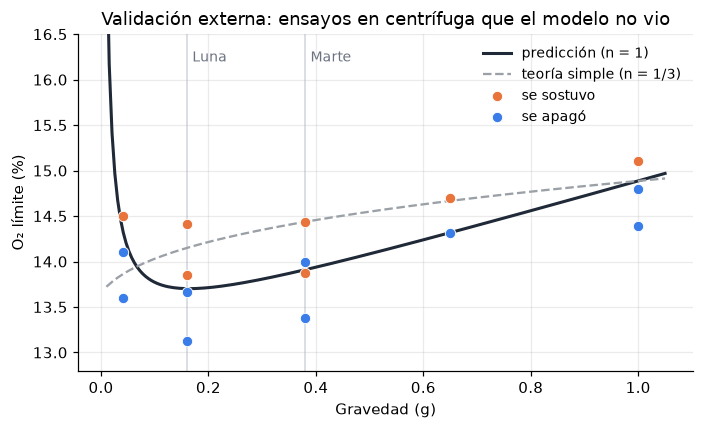

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4))
gg = np.linspace(0.01, 1.05, 200)
ax.plot(gg, limit(u_eff(0, gg, N_EXP)), color="#1f2937", lw=2, label=f"predicción (n = {N_EXP:g})")
ax.plot(gg, limit(u_eff(0, gg, 1 / 3)), color="#9aa0a6", lw=1.5, ls="--", label="teoría simple (n = 1/3)")
for y, c, lab in [(1, BURN, "se sostuvo"), (0, EXT, "se apagó")]:
    d = pg[pg.y == y]
    ax.scatter(d.g, d.o2_pct, c=c, s=46, edgecolor="white", linewidth=0.6, label=lab, zorder=3)
for gl, name in [(0.16, "Luna"), (0.38, "Marte")]:
    ax.axvline(gl, color="#d1d5db", lw=1, zorder=0); ax.text(gl + 0.01, 16.2, name, fontsize=9, color="#6b7280")
ax.set(ylim=(12.8, 16.5), xlabel="Gravedad (g)", ylabel="O₂ límite (%)", title="Validación externa: ensayos en centrífuga que el modelo no vio")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "validacion_gravedad.png", bbox_inches="tight"); plt.show()

### Incertidumbre (Monte Carlo, 2000 muestras)
Combinamos tres fuentes: el exponente $n$ (según los folds), el flujo de flotación a 1 g ($U_b$ entre 15 y 25 cm/s) y un corrimiento de la curva con desvío igual al error medio de validación.

In [9]:
MC = 2000
mc_n = rng.choice(list(chosen.values()), MC) + rng.normal(0, 0.05, MC)
mc_ub = rng.uniform(15, 25, MC)
mc_shift = rng.normal(0, max(mae_loo, 0.15), MC)

def mc(f):
    vals = np.array([f(n, ub, sh) for n, ub, sh in zip(mc_n, mc_ub, mc_shift)])
    return float(f(N_EXP, UB, 0.0)), float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

## 3. Las cinco predicciones

In [10]:
GRAV = {"0 g (ISS)": 0.0, "Luna (0.16 g)": 0.16, "Marte (0.38 g)": 0.38, "Tierra (1 g)": 1.0}
SCEN = {"iss": ("ISS / Orion", 21, 10, 0.0), "rover": ("Rover lunar", 30, 5, 0.16), "moonbase": ("Base lunar", 34, 5, 0.16),
        "mars": ("Hábitat en Marte", 34, 5, 0.38)}
flows = np.r_[0.0, np.geomspace(0.05, 60, 400)]
RESIDUAL = 0.1

pred = {"model": {"A": ABC[0], "B": ABC[1], "C": ABC[2], "s": S_NOISE, "Ub": UB, "n": N_EXP, "u_star": U_STAR,
                  "mc": np.c_[mc_n[:300], mc_ub[:300], mc_shift[:300]].round(4).tolist()}, "gravity": {}, "habitats": {}}
for name, g in GRAV.items():
    loc = mc(lambda n, ub, sh: limit(u_eff(flows, g, n, ub), shift=sh).min())
    natural = mc(lambda n, ub, sh: float(ub * g ** n))
    worst = mc(lambda n, ub, sh: float(flows[limit(u_eff(flows, g, n, ub), shift=sh).argmin()]))
    cut = mc(lambda n, ub, sh: float(limit(u_eff(RESIDUAL, g, n, ub), shift=sh)))
    pred["gravity"][name] = {"g": g, "loc": loc, "natural_flow": natural, "worst_vent": worst, "limit_vent_cut": cut}
    print(f"{name:15s} | O₂ mínimo: {loc[0]:.2f} % (IC {loc[1]:.2f}–{loc[2]:.2f}) | flujo que genera la gravedad: {natural[0]:.1f} cm/s "
          f"| ventilación más peligrosa: {worst[0]:.1f} cm/s | límite cortando la ventilación: {cut[0]:.1f} % (IC {cut[1]:.1f}–{cut[2]:.1f})")

0 g (ISS)       | O₂ mínimo: 13.70 % (IC 13.38–14.03) | flujo que genera la gravedad: 0.0 cm/s | ventilación más peligrosa: 3.3 cm/s | límite cortando la ventilación: 22.3 % (IC 22.0–22.6)
Luna (0.16 g)   | O₂ mínimo: 13.70 % (IC 13.40–14.05) | flujo que genera la gravedad: 3.2 cm/s | ventilación más peligrosa: 0.7 cm/s | límite cortando la ventilación: 13.7 % (IC 13.4–14.1)
Marte (0.38 g)  | O₂ mínimo: 13.91 % (IC 13.56–14.35) | flujo que genera la gravedad: 7.6 cm/s | ventilación más peligrosa: 0.0 cm/s | límite cortando la ventilación: 13.9 % (IC 13.6–14.4)
Tierra (1 g)    | O₂ mínimo: 14.89 % (IC 14.33–15.44) | flujo que genera la gravedad: 20.0 cm/s | ventilación más peligrosa: 0.0 cm/s | límite cortando la ventilación: 14.9 % (IC 14.3–15.4)


In [11]:
for key, (label, o2, flow, g) in SCEN.items():
    pb = mc(lambda n, ub, sh: float(p_burn(o2, u_eff(flow, g, n, ub), sh)))
    margin = mc(lambda n, ub, sh: o2 - float(limit(u_eff(flow, g, n, ub), shift=sh)))
    p_cut = mc(lambda n, ub, sh: float(p_burn(o2, u_eff(RESIDUAL, g, n, ub), sh)))
    pred["habitats"][key] = {"label": label, "o2": o2, "flow": flow, "g": g, "p_burn": pb, "margin": margin, "p_burn_vent_cut": p_cut}
    print(f"{label:17s} O₂ {o2}% | P(se sostiene) = {pb[0]:.3f} | margen: {margin[0]:+.1f} pts (IC {margin[1]:+.1f} a {margin[2]:+.1f}) "
          f"| si se corta la ventilación: P = {p_cut[0]:.3f}")

ISS / Orion       O₂ 21% | P(se sostiene) = 0.955 | margen: +6.9 pts (IC +6.6 a +7.2) | si se corta la ventilación: P = 0.362
Rover lunar       O₂ 30% | P(se sostiene) = 0.999 | margen: +16.2 pts (IC +15.8 a +16.5) | si se corta la ventilación: P = 0.999
Base lunar        O₂ 34% | P(se sostiene) = 1.000 | margen: +20.2 pts (IC +19.8 a +20.5) | si se corta la ventilación: P = 1.000
Hábitat en Marte  O₂ 34% | P(se sostiene) = 1.000 | margen: +20.0 pts (IC +19.6 a +20.3) | si se corta la ventilación: P = 1.000


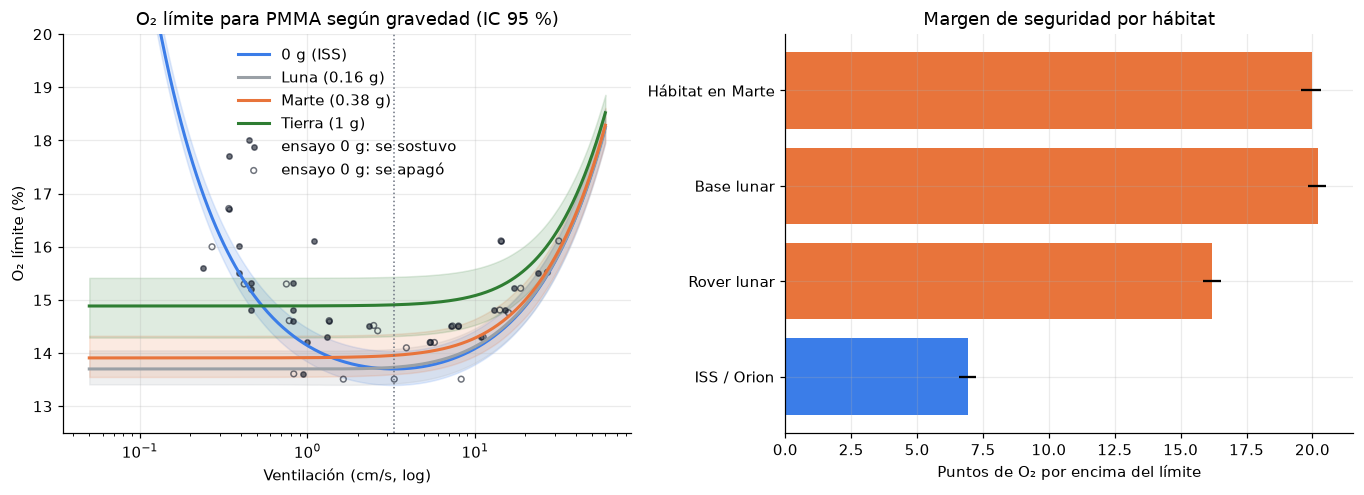

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
for (name, g), c in zip(GRAV.items(), ["#3b7de8", "#9aa0a6", "#e8743b", "#2e7d32"]):
    band = np.array([limit(u_eff(flows[1:], g, n, ub), shift=sh) for n, ub, sh in zip(mc_n[:400], mc_ub[:400], mc_shift[:400])])
    ax[0].fill_between(flows[1:], *np.percentile(band, [2.5, 97.5], axis=0), color=c, alpha=0.15)
    ax[0].plot(flows[1:], limit(u_eff(flows[1:], g, N_EXP)), color=c, lw=2, label=name)
ax[0].scatter(ug.flow_cm_s[ug.y == 1], ug.o2_pct[ug.y == 1], c="#111827", s=12, alpha=0.6, label="ensayo 0 g: se sostuvo")
ax[0].scatter(ug.flow_cm_s[ug.y == 0], ug.o2_pct[ug.y == 0], facecolors="none", edgecolors="#111827", s=14, alpha=0.6, label="ensayo 0 g: se apagó")
ax[0].axvline(U_STAR, color="#6b7280", lw=1, ls=":")
ax[0].set(xscale="log", ylim=(12.5, 20), xlabel="Ventilación (cm/s, log)", ylabel="O₂ límite (%)", title="O₂ límite para PMMA según gravedad (IC 95 %)")
ax[0].legend(frameon=False)
labels = [v["label"] for v in pred["habitats"].values()]
m = np.array([v["margin"] for v in pred["habitats"].values()])
ax[1].barh(labels, m[:, 0], xerr=[m[:, 0] - m[:, 1], m[:, 2] - m[:, 0]], color=["#3b7de8" if x < 10 else "#e8743b" for x in m[:, 0]])
ax[1].axvline(0, color="k", lw=1)
ax[1].set(xlabel="Puntos de O₂ por encima del límite", title="Margen de seguridad por hábitat")
fig.tight_layout(); fig.savefig(FIG / "predicciones.png", bbox_inches="tight"); plt.show()

**Qué dicen las predicciones**
1. **Probabilidad**: en todos los hábitats de Artemis, un material como el PMMA que se prende sigue quemando (P ≈ 1).
2. **O₂ mínimo**: en la Luna y en Marte ronda 13.6-13.9 %, igual o **menor** que en la ISS. Las atmósferas planeadas (30-34 %) quedan muy arriba.
3. **Ventilación más peligrosa**: en 0 g, ~3.3 cm/s. En la Luna, la gravedad sola mueve el aire a ~3 cm/s: **la base lunar vive justo en el punto más peligroso de la curva**.
4. **Cortar la ventilación**: en la ISS, si el aire queda casi quieto, el límite sube por encima de 21 % y la llama se ahoga. En la Luna y Marte no: la gravedad sigue soplando y el límite apenas cambia.
5. **Margen**: +7 puntos en la ISS, +16 en el rover y ~+20 en la base lunar y Marte. No se puede bajar el O₂ hasta un nivel no inflamable sin asfixiar a la tripulación, así que la seguridad depende de **elegir materiales, detectar temprano y suprimir**.

**Límites.** Un solo material (PMMA en varillas). Datos a ~1 atm: a 8.2 psi los materiales suelen quemar algo menos, así que la predicción queda del lado seguro. Fuera de 13-18 % de O₂ el modelo extrapola con la física y no con datos.

## 4. Importancia de variables (XGBoost híbrido) y extrapolación

In [13]:
mh = xgb().fit(pd.DataFrame({"O2": ug.o2_pct, "u_ef": ug.flow_cm_s}), ug.y)
print(pd.Series(mh.get_booster().get_score(importance_type="gain")).sort_values().round(2))
xg = xgb().fit(ug[["o2_pct", "flow_cm_s"]], ug.y)
for o2 in [18, 21, 25, 30, 34, 40]:
    print(f"O₂ {o2:>2}% con aire quieto (0.1 cm/s) → XGBoost: {xg.predict_proba([[o2, 0.1]])[0, 1]:.2f} | física: {p_burn(o2, 0.1):.2f}")

O2      0.54
u_ef    0.60
dtype: float64
O₂ 18% con aire quieto (0.1 cm/s) → XGBoost: 0.64 | física: 0.13
O₂ 21% con aire quieto (0.1 cm/s) → XGBoost: 0.64 | física: 0.36
O₂ 25% con aire quieto (0.1 cm/s) → XGBoost: 0.64 | física: 0.77
O₂ 30% con aire quieto (0.1 cm/s) → XGBoost: 0.64 | física: 0.97
O₂ 34% con aire quieto (0.1 cm/s) → XGBoost: 0.64 | física: 0.99
O₂ 40% con aire quieto (0.1 cm/s) → XGBoost: 0.64 | física: 1.00


Todos los datos de entrenamiento están entre 13 y 18 % de O₂. A 34 %, XGBoost repite lo último que vio; la física extiende la tendencia. Ningún ensayo con materiales se hizo ahí: **esa es la brecha de datos que muestra el atlas**.

In [14]:
pred["validation"] = {"cv_interp": cv_interp.reset_index().rename(columns={"index": "model"}).to_dict("records"),
                      "cv_block": cv_block.reset_index().rename(columns={"index": "model"}).to_dict("records"),
                      "external": ext_tbl.reset_index().rename(columns={"index": "model"}).to_dict("records"),
                      "n_train": int(len(ug)), "n_external": int(len(pg)), "noise_pairs": len(conflicts),
                      "acc_nasa_curve": acc_nasa, "noise_ceiling": ceiling, "curve_max_err": float(curve_err.max()),
                      "mae_theory": mae_theory, "mae_loo": mae_loo, "n_by_fold": {str(k): v for k, v in chosen.items()},
                      "boundary_by_g": obs.round(3).to_dict("records"),
                      "pg_points": pg[["g", "o2_pct", "y"]].to_dict("records")}
pred["sources"] = ["Olson S.L., Ferkul P.V., Combust. Flame 180 (2017) 217-229; NASA/TM-20210011385 (BASS-II)",
                   "Olson S.L. et al., Fire Safety Journal (2024): ensayos en centrífuga a gravedad parcial"]
out = HERE.parent / "lib" / "predictions.json"
out.write_text(json.dumps(pred, ensure_ascii=False, indent=1, default=float))
print("Exportado a", out)

Exportado a /Users/oletini/Proyectos/flame-in-freefall/lib/predictions.json
